# Synapse Task 4B

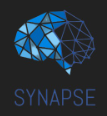

i know it's been an exhausting ride but neural networks are used everywhere around you, you just don’t know it.

eg) detecting water leaks underground 💧, predicting bridge failures 🌉, identifying counterfeit medicines 💊, detecting illegal fishing 🐟, predicting wildfires 🔥, diagnosing machine failures ⚙️, detecting oil spills from satellites 🛰️, predicting crop diseases 🌾, identifying counterfeit art 🎨, detecting methane leaks 💨, predicting landslides ⛰️, monitoring glaciers 🧊, estimating battery degradation 🔋, detecting earthquake signals 🌍, identifying fake diamonds 💎, predicting sewer blockages 🚰, detecting structural damage 🏗️, monitoring livestock health 🐄, identifying illegal logging 🌳, predicting food waste 🥬 and so many more. so lock in.


Datasets: same ones will be used :))

## convolutional neural networks!!

cnns are a special type of neural network designed to roughly mimic how human vision works 👀. they use a key operation called convolution, which in mathematics combines two functions to produce a third function that captures how one function is influenced by the other 🤯.

in convolutional neural networks, this operation helps identify important patterns and features in images 🖼️🔍. a cnn is made up of multiple layers of artificial neurons that progressively learn more complex visual features 📈. you can read more about them on...
 http://cs231n.github.io/convolutional-networks/ (read it completely its cool)

for the people who wanna try seeing an actual image flow layer by layer via a cnn
https://poloclub.github.io/cnn-explainer/

if you feel like visually looking at this : https://www.youtube.com/watch?v=KuXjwB4LzSA or https://www.youtube.com/watch?v=pj9-rr1wDhM

then ofcourse our fav :
https://youtu.be/HGwBXDKFk9I?si=2EcTgw-rhnParZly

dig deep guys could be overwhelming but try to focus on how beautiful 🧚🏻‍♀️

q. fun fact 🤭 what every dl library calls "convolution" is technically *cross-correlation*. find out the difference (it's literally one flip) and why nobody cares

**But when should you use a Convolutional Neural Network instead of a plain (dense) Artificial Neural Network?**

1. CNNs work best when the data can be represented in a spatial manner, say an image in MxN pixels. If your data is just as useful after shuffling any of your columns with each other then a CNN won't help you.
2. For example take into consideration the titanic dataset which you worked on. It had columns (or features) like age and gender, and if I were to swap those two columns (before feeding it to my network) it would make no difference whatsoever to my dataset. Plain ANNs are preferred for such datasets
3. On the contrary, if we were to swap the columns (which are essentially pixel arrays) in an image, we are surely going to mess up an actual image. A plain ANN can still kinda work on small images (you did mnist in 4A!), but it throws away where pixels are, so CNNs do way better.

 a 32×32×3 image into a dense layer of 1000 neurons = how many weights? 🤯 now how many weights does a Conv2D with 32 filters of size 3×3 have? why is the difference so huge?

Let's use CNN on the CIFAR Dataset

Let's use CNN on the CIFAR Dataset

In [ ]:
import tensorflow as tf

from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

### Download and prepare the CIFAR10 dataset


The CIFAR10 dataset contains 60,000 color images in 10 classes, with 6,000 images in each class. The dataset is divided into 50,000 training images and 10,000 testing images. The classes are mutually exclusive and there is no overlap between them.

In [ ]:
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalize pixel values to be between 0 and 1


### Verify the data

To verify that the dataset looks correct, let's plot the first 25 images from the training set and display the class name below each image:


### Create the convolutional base

The lines of code below define the convolutional base using a common pattern: a stack of [Conv2D](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Conv2D) and [MaxPooling2D](https://www.tensorflow.org/api_docs/python/tf/keras/layers/MaxPool2D) layers.

As input, a CNN takes tensors of shape (image_height, image_width, color_channels), ignoring the batch size. If you are new to these dimensions, color_channels refers to (R,G,B). In this example, you will configure your CNN to process inputs of shape (32, 32, 3), which is the format of CIFAR images. You can do this by passing the argument `input_shape` to your first layer.


In [ ]:
model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model.add(layers.MaxPooling2D((2, 2)))
# Now add another Conv2D followed by a MaxPool and another Conv2D... set the parameters according to what feels right to you and give a justification for the same


Let's display the architecture of your model so far:

In [ ]:
model.summary()

Above, you can see that the output of every Conv2D and MaxPooling2D layer is a 3D tensor of shape (height, width, channels). The width and height dimensions tend to shrink as you go deeper in the network. The number of output channels for each Conv2D layer is controlled by the first argument (e.g., 32 or 64). Typically,  as the width and height shrink, you can afford (computationally) to add more output channels in each Conv2D layer.

### Add Dense layers on top

To complete the model, you will feed the last output tensor from the convolutional base (of shape (4, 4, 64)) into one or more Dense layers to perform classification. Dense layers take vectors as input (which are 1D), while the current output is a 3D tensor. First, you will flatten (or unroll) the 3D output to 1D,  then add one or more Dense layers on top. CIFAR has 10 output classes, so you use a final Dense layer with 10 outputs.

ps: keep the last Dense layer without an activation. it'll give raw scores (logits), so we tell the loss `from_logits=True` below 👀

Here's the complete architecture of your model:

In [ ]:
model.summary()

The network summary shows that (4, 4, 64) outputs were flattened into vectors of shape (1024) before going through two Dense layers.

### Compile and train the model (Might take around 10-15 minutes)

In [ ]:
model.compile(optimizer=, # Set Optimizer as adam
              loss=, # Use Sparse categorical crossentropy as loss
              metrics=) # Use accuracy as the metric

history = model.fit(train_images, train_labels, epochs=10,
                    validation_data=(test_images, test_labels))

### Evaluate the model

In [ ]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')

test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)

In [ ]:
print(test_acc)

Your simple CNN has achieved a test accuracy, which may not be the best. But also not bad for a few lines of code!

q. look at the plot. at some point accuracy keeps going up but val_accuracy stops 👀 what's happening there? name 2 things you could add to fix it.

so now let's try something different, instead of training a model from scratch let's use a pretrained model and train a small head on top of it and then finetune it. this is something we call as **transfer learning**
let's dig deeper :

https://cs231n.github.io/transfer-learning/

https://keras.io/guides/transfer_learning/

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Load a pretrained model, excluding its final classification layer
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights='imagenet'
)

# Freeze the base model so we don't destroy its learned weights
base_model.trainable =                                    # (True or False? think about why)

model = models.Sequential([
    layers.Resizing(96, 96),                                    # MobileNetV2 expects at least 96x96
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation= ),
    layers.Dense(10, activation= )  # 10 CIFAR classes
])

model.compile(
    optimizer=
    loss=
    metrics=
)

# Train for a few epochs and compare accuracy + training time
# against your from-scratch CNN

mobilenet was trained on imagenet (dogs, cars, cups...) not cifar. so why does it still help so much? 🤯 and why do we need a tiny learning rate when we unfreeze it?

## recurrent neural networks!!

(personal fav)


In a recurrent neural network we store the output activations from one or more of the layers of the network. Often these are hidden later activations. Then, the next time we feed an input example to the network, we include the previously-stored outputs as additional inputs. You can think of the additional inputs as being concatenated to the end of the “normal” inputs to the previous layer.

the thing that first got a generation of people excited was : https://karpathy.github.io/2015/05/21/rnn-effectiveness/

A regular feedforward network (what you built in 4A) has no memory, every input is processed independently. That's a problem the moment order matters: "not bad, actually great" and "not great, actually bad" have the same words, different meaning, purely because of order.

An RNN fixes this by reusing the same weights at every timestep and carrying a hidden state forward — a running summary of everything it has seen in the sequence so far. Read one word, update the hidden state, read the next word, update again, and so on until the sequence ends.

A simple explanation of RNN :
https://www.youtube.com/watch?v=UNmqTiOnRfg&t=3s

our goat is back and never disappoints: https://www.youtube.com/watch?v=LHXXI4-IEns

let's try it for a mini problem

In [ ]:
import numpy as np

vocab = ["good", "bad", "not", "movie", "great"]
vocab_size = len(vocab)
hidden_size = 3   # feel free to change this later and see what happens

def one_hot(word):
    # Return a (vocab_size, 1) column vector with a 1 at the word's index
    # and 0s everywhere else
    pass

sentences = [
    ["not", "bad", "movie"],     # y = 1 (mixed but leaning positive)
    ["great", "good", "movie"],  # y = 1
    ["bad", "bad", "movie"],     # y = 0
]
labels = [1, 1, 0]

X = [[one_hot(w) for w in sent] for sent in sentences]
y = labels

In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_deriv(a):
    # derivative of sigmoid, written in terms of the activation itself (a)
    pass

class RNNFromScratch:
    def __init__(self, vocab_size, hidden_size):
        self.hidden_size = hidden_size
        # Wi: input -> hidden      what shape?
        # Wh: hidden -> hidden     what shape?
        # Wo: hidden -> output     what shape?
        self.Wi = None
        self.Wh = None
        self.Wo = None

    def forward(self, x_seq):
        """
        Steps:
        1. h[0] should be a zero vector - the "empty memory" before reading
           anything
        2. For each timestep t, combine the input at t with the PREVIOUS
           hidden state, apply an activation - this gives you h[t+1]
        3. After the loop, compute a single output using ONLY the final
           hidden state
        Return both the full list of hidden states AND the output - you
        will need every h[t] for the backward pass.
        """
        T = len(x_seq)
        h = None   # list of hidden states, starting with h[0] = zeros
        # your loop here

        o = None   # final sigmoid output
        return h, o

    def backward(self, x_seq, h, o, y_true, learning_rate):
        """
        This is BPTT. Recall from the article:
        - dL/dWo has ONE path to the loss (no recurrence involved)
        - dL/dWi and dL/dWh are SHARED across every timestep, so their
          gradients are a SUM of contributions - one per timestep - by the
          total derivative rule
        - the Jacobian dh_t/dh_(t-1) is diagonal, because the activation is
          applied elementwise (this means: elementwise multiply, not a full
          matrix product, when you get to that step)

        Structure to follow:
        1. Compute dL/dWo directly (no loop needed)
        2. Initialize a "delta" that represents dL/dh_T
        3. Loop backward through time (t = T-1 down to 0):
             - turn delta into the gradient w.r.t. the pre-activation at t
             - accumulate that timestep's contribution into dL_dWi and dL_dWh
             - propagate delta one more step back through Wh
        4. Update all three weight matrices with gradient descent
        """
        T = len(x_seq)

        # dL/dWo
        dL_dWo = None

        # dL/dWi and dL/dWh
        delta = None   # dL/dh_T

        dL_dWi = np.zeros_like(self.Wi)
        dL_dWh = np.zeros_like(self.Wh)

        for t in reversed(range(T)):
            # your BPTT step here
            pass

        # gradient descent update
        pass

    def predict(self, x_seq):
        # Run forward(), return 1 if the output >= 0.5 else 0
        pass

    def train(self, X, y, learning_rate, epochs):
        # For each epoch, loop through every sequence in X:
        #   - forward pass
        #   - compute binary cross-entropy loss
        #   - backward pass
        # Print the total loss every 20 epochs so you can watch it learn
        pass

In [ ]:
rnn = RNNFromScratch(vocab_size, hidden_size)
rnn.train(X, y, learning_rate=# , epochs= )

for i, seq in enumerate(sentences):
    pred = rnn.predict(X[i])
    print(f"Sentence: {seq}\tActual: {y[i]}\tPredicted: {pred}")

the predictions should be good since its a toy problem and fitting should be easy

look at our 3 sentences again. is there any pair with the same words in a different order? 🤔 so does this data even prove the rnn *remembers order*? add 2 sentences that actually test it and see if your rnn still gets them.

switch to keras for anything dataset size and try it for a real dataset.

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, datasets

vocab_size_real =   # pick a vocabulary size
max_len =            # pick a sequence length - keep it SHORT for now

(x_train, y_train), (x_test, y_test) = datasets.imdb.load_data(num_words=vocab_size_real)
x_train = tf.keras.preprocessing.sequence.pad_sequences(x_train, maxlen=max_len)
x_test = tf.keras.preprocessing.sequence.pad_sequences(x_test, maxlen=max_len)

model = models.Sequential([
    # 1. An Embedding layer - what two arguments does it need?
    # 2. A SimpleRNN layer - how many units?
    # 3. A Dense output layer - what activation, for a binary label?
])

model.compile(
    optimizer=
    loss=
    metrics=

history = model.fit(
    x_train, y_train,
    epochs=
    batch_size=
    validation_data=(x_test, y_test)
)

# Evaluate on the test set and print the accuracy

now this is ground breaking right? but like all good things let's understand why its all wrong and useless

In [ ]:
# Rebuild the same model architecture as above, but on longer sequences.
# Reuse your code as a starting point - the only thing that should change is max_len and the padded data.

compare the validation accuracy curve here against the short-sequence run.
the longer-sequence RNN trains slower, plateaus lower, or even looks unstable (loss jumping around).

what happened to your accuracy when you increased max_len?

If it clearly got worse - you get a chocolate!! 🍫
Time to find out why.

read this article in depth to understand where and why rnns break? written by yours truly.
https://medium.com/@maheksanghvi2006/backpropagation-through-time-isnt-complicated-until-it-is-4fb2ebf55d61

just a sneak peak into whattodo if rnns fail?

https://colah.github.io/posts/2015-08-Understanding-LSTMs/

if this gets you excited, lstm is a fun concept to study deeper :

https://colah.github.io/posts/2015-08-Understanding-LSTMs/

https://youtu.be/z7IPBg6MyrU?si=DacDQIlEcauAJlLE

https://youtu.be/Akv3poqqwI4?si=K8Q0B9NRF0XeUjL5

https://youtu.be/fiqo6uPCJVI?si=y4Nszi3WUPuBZQNU

Generative Adversarial Networks!!

(last one i promise)

a gan is basically two neural networks competing against each other 🎭. the generator starts with random noise and tries to turn it into something that looks real, like a handwritten digit. the discriminator looks at the image and tries to figure out whether it’s real or generated. they train together, so as the generator gets better at fooling the discriminator, the discriminator gets better at spotting the fakes. eventually, the generator gets so good that its outputs can look surprisingly real.


ofcourse a vid to understand better : https://www.youtube.com/watch?v=r9mfSrRIFnM

just a toy example : a tiny 1d gan where the “real data” is just numbers sampled from a normal distribution centered around 5 📊. the generator starts with completely random noise and has to learn how to produce numbers that follow the same distribution. basically, it starts with no clue what the real data looks like and slowly learns to imitate it.


In [ ]:
import numpy as np

def real_data(n):
    # Sample n numbers from a normal distribution centered at 5
    pass

def noise(n):
    # Sample n numbers of random noise the generator will transform
    # (any distribution is fine - e.g. uniform between -1 and 1)
    pass

class TinyGenerator:
    def __init__(self):
        # A single weight and bias is enough for this toy problem
        self.w =
        self.b =

    def generate(self, z):
        # Turn noise z into a "fake" number
        pass

class TinyDiscriminator:
    def __init__(self):
        self.w =
        self.b =

    def predict(self, x):
        # Output a probability that x is real (use sigmoid)
        pass

# Training loop:
# 1. Sample a batch of real numbers and a batch of fake numbers (from the generator)
# 2. Train the discriminator to tell them apart
# 3. Train the generator to fool the (now slightly better) discriminator
# 4. Repeat
#
# You don't need full backprop through matrices here - with a single
# weight and bias each, work out the gradients by hand on paper first,
# then code the update rule.

## RESEARCH

Find out all about transformers and what are they? it was an earth shattering concept when it came out in a revolunizing paper

https://arxiv.org/pdf/1706.03762

give it time it is a fun read.

while reading, find out why attention divides by √d_k 👀 (hint: what's the variance of a dot product of two random vectors with d_k entries?)

# **End of Task**

> ©DJS Synapse 2025 - 2026